# HW2-Continuous Attractor Neural Network (CANN)

## 作业说明

**实验目的**：本作业旨在帮助你理解 Continuous Attractor Neural Network (CANN) 的核心方程及其动力学过程。通过补全代码，你将亲手实现一维和二维连续吸引子神经网络。

**准备工作**：
1. 下载文件：请先将本作业附件 HW2-CANN_Model.ipynb 下载到本地电脑。
2. 运行环境：推荐使用 VS Code 打开。请确保已安装必要的库（如 brainpy, canns, matplotlib, numpy 等）。

**操作步骤**：
1. 补全代码：请仔细阅读代码块中的注释说明，在标注了 `# TODO` 的地方填入正确的表达式或参数。对于模型实现，确保你正确实现了连接矩阵构建 (`make_conn`)、刺激生成 (`get_stimulus_by_pos`) 和网络更新 (`update`) 等方法。
3. 运行仿真：完成代码补全后，点击"Run All Cells"运行所有单元格。
4. 结果分析：观察生成的动画和可视化图，确认CANN的活动bump是否正确形成和追踪输入。

**提交指南**：
1. 保留输出：提交前请确认 Notebook 中已经显示了仿真生成的动画和结果。
2. 命名规范：请将文件名重命名为：HW2-学号-姓名.ipynb。

## Part 1: 1D Continuous Attractor Neural Network (CANN_1D)

In [1]:
import brainpy as bp
import brainpy.math as bm
import numpy as np
import matplotlib.pyplot as plt

from canns.task.tracking import SmoothTracking1D
from canns.analyzer.visualization import PlotConfigs, energy_landscape_1d_animation

bm.set_dt(dt=0.1)


class CANN_1D(bp.DynamicalSystem):
    """1D连续吸引子神经网络模型。"""

    def __init__(
        self,
        num: int,
        tau: float = 1.0,
        k: float = 8.1,
        a: float = 0.5,
        A: float = 10,
        J0: float = 4.0,
        z_min: float = -bm.pi,
        z_max: float = bm.pi,
    ):
        super().__init__()

        self.tau = tau
        self.k = k
        self.a = a
        self.A = A
        self.J0 = J0
        self.z_min = z_min
        self.z_max = z_max
        self.z_range = z_max - z_min

        # 特征空间
        # TODO: 使用bm.linspace创建特征坐标数组self.x，范围从z_min到z_max
        self.x = bm.linspace(z_min, z_max, num)
        # TODO: 计算self.rho (神经密度 = num / z_range) 和 self.dx (刺激密度 = z_range / num)
        self.rho = num / self.z_range
        self.dx = self.z_range / num

        # 连接矩阵
        # TODO: 调用self.make_conn()创建连接矩阵
        self.conn_mat = self.make_conn()

        # 状态变量
        self.shape = (num,)  # 兼容canns task接口
        # TODO: 使用bm.Variable初始化self.r和self.u，形状为(num,)
        self.r = bm.Variable(bm.zeros(self.shape))
        self.u = bm.Variable(bm.zeros(self.shape))
        # TODO: 使用bm.Variable初始化self.inp，形状为(num,)
        self.inp = bm.Variable(bm.zeros(self.shape))

    def dist(self, d):
        """计算圆环特征空间中的最短距离。"""
        d = bm.remainder(d, self.z_range)
        d = bm.where(d > self.z_range / 2, d - self.z_range, d)
        return d

    def make_conn(self):
        """构建连接矩阵。"""
        # TODO: 计算神经元对之间的距离矩阵
        x_left = bm.reshape(self.x, (-1, 1))
        x_right = bm.repeat(self.x.reshape((1, -1)), len(self.x), axis=0)
        d = self.dist(x_left - x_right)
        # TODO: 使用高斯函数计算连接强度
        # 公式: J0 * exp(-0.5 * (d/a)^2) / (sqrt(2*pi) * a)
        return (
            self.J0 * bm.exp(-0.5 * bm.square(d / self.a)) / (bm.sqrt(2 * bm.pi) * self.a) 
        )

    def get_stimulus_by_pos(self, pos):
        """生成以给定位置为中心的高斯形外部刺激。"""
        # TODO: 实现刺激生成
        # 提示: A * exp(-0.25 * (dist(x - pos) / a)^2)
        return  (
            self.A * bm.exp(-0.25 * bm.square(self.dist(self.x - pos) / self.a))
        )

    def update(self, inp):
        """推进网络一个时间步。"""
        # TODO: 更新self.inp为外部输入
        self.inp.value = inp
        # TODO: 计算发放率 r = u^2 / (1 + k * sum(u^2))
        r1 = bm.square(self.u.value)
        r2 = 1.0 + self.k * bm.sum(r1)
        self.r.value = r1 / r2
        # TODO: 计算循环输入 I_rec = conn_mat @ r
        I_rec = bm.dot(self.conn_mat, self.r.value)
        # TODO: 使用欧拉法更新u: u += (-u + I_rec + inp) / tau * dt
        self.u.value += ((-self.u.value + I_rec + inp) / self.tau * bm.get_dt())


# ============== 测试 CANN_1D ==============
print("Testing CANN_1D...")

cann = CANN_1D(
    num=512,
    tau=1.0,
    k=8.1,
    a=0.5,
    A=10.0,
    J0=4.0,
    z_min=-bm.pi,
    z_max=bm.pi,
)

print(f"Connectivity matrix shape: {cann.conn_mat.shape}")

# 使用SmoothTracking1D生成输入序列
task = SmoothTracking1D(
    cann_instance=cann,
    Iext=(0., 0., np.pi, 2 * np.pi),
    duration=(2., 20., 20.),
    time_step=bm.get_dt(),
)
task.get_data()

print(f"Task data shape: {task.data.shape}")

# 定义仿真步骤函数
def run_step(t, inputs):
    cann(inputs)
    return cann.r.value, cann.u.value

# 使用bm.for_loop进行仿真
rs, us = bm.for_loop(
    run_step,
    (task.run_steps, task.data),
    progress_bar=True
)

print(f"CANN_1D simulation completed! Shape: {rs.shape}")

c:\Users\Lynn\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Testing CANN_1D...
Connectivity matrix shape: (512, 512)


<SmoothTracking1D> Generating Task data: 420it [00:00, 1211.26it/s]


Task data shape: (420, 512)
CANN_1D simulation completed! Shape: (420, 512)


  0%|          | 0/420 [00:00<?, ?it/s]

Running for 420 iterations: 100%|██████████| 420/420 [00:00<00:00, 23875.52it/s]


c:\Users\Lynn\AppData\Local\Programs\Python\Python312\Lib\site-packages\canns\analyzer\visualization\energy_plots.py:585: UserWarning: Failed to generate HTML5 video (FFmpeg may not be installed): Requested MovieWriter (ffmpeg) not available
Falling back to jshtml format. Install FFmpeg for better performance:
  conda install -c conda-forge ffmpeg  OR  brew install ffmpeg
  display_animation_in_jupyter(ani)


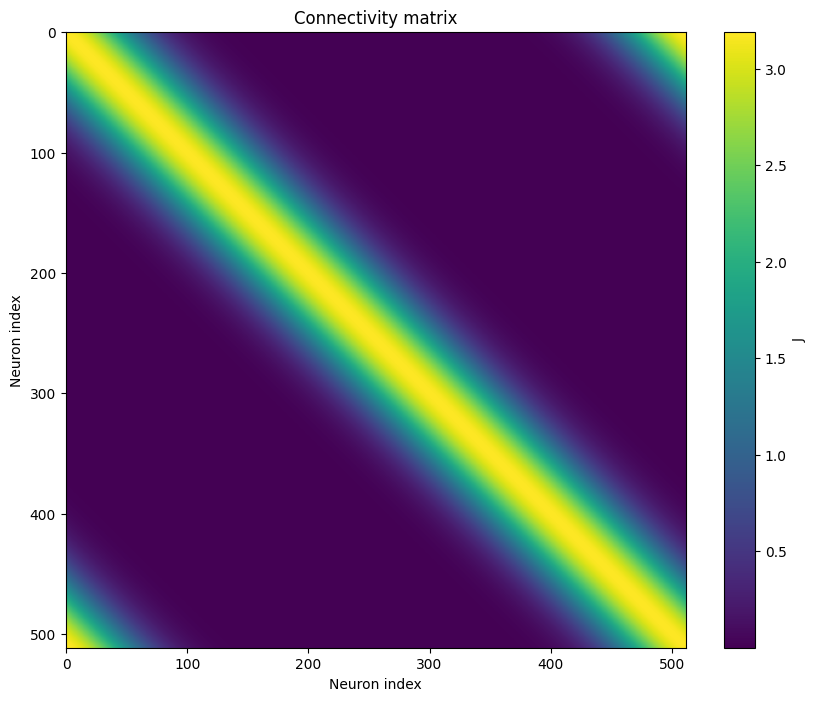

In [2]:
# 可视化 - 使用canns库的animation工具
config = PlotConfigs.energy_landscape_1d_animation(
    time_steps_per_second=100,
    fps=20,
    title='CANN_1D: Smooth Tracking',
    xlabel='State (position)',
    ylabel='Activity',
    repeat=False,
    show=True,
    save_path=None,
)

energy_landscape_1d_animation(
    data_sets={'u': (cann.x, us), 'Iext': (cann.x, task.data)},
    config=config
)

# 连接矩阵可视化
plt.figure(figsize=(10, 8))
plt.imshow(bm.as_numpy(cann.conn_mat), cmap='viridis', aspect='auto')
plt.colorbar(label='J')
plt.xlabel('Neuron index')
plt.ylabel('Neuron index')
plt.title('Connectivity matrix')
plt.show()

## Part 2: 2D Continuous Attractor Neural Network (CANN_2D)

In [7]:
import jax

from canns.task.tracking import SmoothTracking2D
from canns.analyzer.visualization import energy_landscape_2d_animation


class CANN_2D(bp.DynamicalSystem):
    """2D连续吸引子神经网络模型。"""

    def __init__(
        self,
        length: int,
        tau: float = 1.0,
        k: float = 8.1,
        a: float = 0.5,
        A: float = 10,
        J0: float = 4.0,
        z_min: float = -bm.pi,
        z_max: float = bm.pi,
    ):
        super().__init__()

        self.length = length
        self.tau = tau
        self.k = k
        self.a = a
        self.A = A
        self.J0 = J0
        self.z_min = z_min
        self.z_max = z_max
        self.z_range = z_max - z_min

        # 特征空间
        # TODO: 创建1D坐标数组self.x
        self.x = bm.linspace(z_min, z_max, length)
        # TODO: 计算self.rho和self.dx
        self.rho = length / self.z_range
        self.dx = self.z_range / length

        # 连接矩阵
        # TODO: 调用self.make_conn()创建2D连接矩阵
        self.conn_mat = self.make_conn()

        # 状态变量 (2D数组)
        self.shape = (length, length)  # 兼容canns task接口
        # TODO: 初始化self.r和self.u为2D数组 (length x length)
        self.r = bm.Variable(bm.zeros(self.shape))
        self.u = bm.Variable(bm.zeros(self.shape))
        # TODO: 初始化self.inp为2D数组
        self.inp = bm.Variable(bm.zeros(self.shape))

    def dist(self, d):
        """计算2D环面空间中的最短距离向量。"""
        box_size = bm.asarray([self.z_range, self.z_range])
        d = bm.remainder(d, box_size)
        d = bm.where(d > box_size / 2, d - box_size, d)
        return d

    def make_conn(self):
        """构建2D连接矩阵。"""
        # TODO: 创建2D网格坐标
        x1, x2 = bm.meshgrid(self.x, self.x)
        # TODO: 将坐标展平并堆叠
        all_coords = bm.stack([x1.flatten(), x2.flatten()]).T
        # TODO: 使用jax.vmap计算每个神经元到所有其他神经元的距离
        @jax.vmap
        def get_conn_for_one_neuron(source_coord):
            diff_vectors = self.dist(source_coord - all_coords)
            scalar_distances = bm.linalg.norm(diff_vectors, axis=1)
            conn_strengths = self.J0 * bm.exp(-0.5 * bm.square(scalar_distances/self.a)) / (bm.sqrt(2*bm.pi) * self.a)
            return conn_strengths
        
        return get_conn_for_one_neuron(all_coords)

    def get_stimulus_by_pos(self, pos):
        """在2D位置生成高斯形外部刺激。"""
        pos = bm.asarray(pos)
        # TODO: 创建2D网格坐标
        x1, x2 = bm.meshgrid(self.x, self.x)
        all_coords = bm.stack([x1.flatten(), x2.flatten()]).T
        # TODO: 计算到刺激中心的距离
        diff_vectors = self.dist(all_coords - pos)
        scalar_distances = bm.linalg.norm(diff_vectors, axis=1)
        # TODO: 生成高斯刺激并reshape回2D网格
        # stimulus = A * exp(-0.25 * (dist/a)^2)
        stimulus = self.A * bm.exp(-0.25 * bm.square(scalar_distances / self.a))
        return stimulus.reshape(self.length, self.length)

    def update(self, inp):
        """推进网络一个时间步。"""
        # TODO: 更新self.inp
        self.inp.value = inp
        # TODO: 计算发放率 r = u^2 / (1 + k * sum(u^2))
        r1 = bm.square(self.u.value) 
        r2 = 1.0 + self.k + bm.sum(r1)
        self.r.value = r1 / r2
        # TODO: 计算2D循环输入 (将r展平与conn_mat相乘，再reshape回length x length)
        I_rec = bm.dot(self.conn_mat, self.r.value.flatten()).reshape(self.length, self.length)
        # TODO: 使用欧拉法更新u
        self.u.value += ((-self.u.value + I_rec + inp) / self.tau * bm.get_dt())

# ============== 测试 CANN_2D ==============
print("Testing CANN_2D...")

grid_size = 64
cann_2d = CANN_2D(
    length=grid_size,
    tau=1.0,
    k=8.1,
    a=0.5,
    A=10.0,
    J0=4.0,
    z_min=-bm.pi,
    z_max=bm.pi,
)

print(f"Connectivity matrix shape: {cann_2d.conn_mat.shape}")

# 使用SmoothTracking2D生成输入序列
task_2d = SmoothTracking2D(
    cann_instance=cann_2d,
    Iext=([0., 0.], [0., 0.], [1., 1.], [0.75, 0.75], [2., 2.]),
    duration=(10., 10., 10., 10.),
    time_step=bm.get_dt(),
)
task_2d.get_data()

print(f"Task data shape: {task_2d.data.shape}")

# 使用bm.for_loop进行仿真
def run_step_2d(t, inputs):
    cann_2d(inputs)
    return cann_2d.r.value, cann_2d.u.value

rs_2d, us_2d = bm.for_loop(
    run_step_2d,
    (task_2d.run_steps, task_2d.data),
    progress_bar=True
)

print(f"CANN_2D simulation completed! Shape: {rs_2d.shape}")

Testing CANN_2D...
Connectivity matrix shape: (4096, 4096)


<SmoothTracking2D> Generating Task data: 400it [00:01, 216.64it/s]


Task data shape: (400, 64, 64)


Running for 400 iterations: 100%|██████████| 400/400 [00:01<00:00, 306.86it/s]

CANN_2D simulation completed! Shape: (400, 64, 64)


c:\Users\Lynn\AppData\Local\Programs\Python\Python312\Lib\site-packages\canns\analyzer\visualization\energy_plots.py:987: UserWarning: Failed to generate HTML5 video (FFmpeg may not be installed): Requested MovieWriter (ffmpeg) not available
Falling back to jshtml format. Install FFmpeg for better performance:
  conda install -c conda-forge ffmpeg  OR  brew install ffmpeg
  display_animation_in_jupyter(ani)


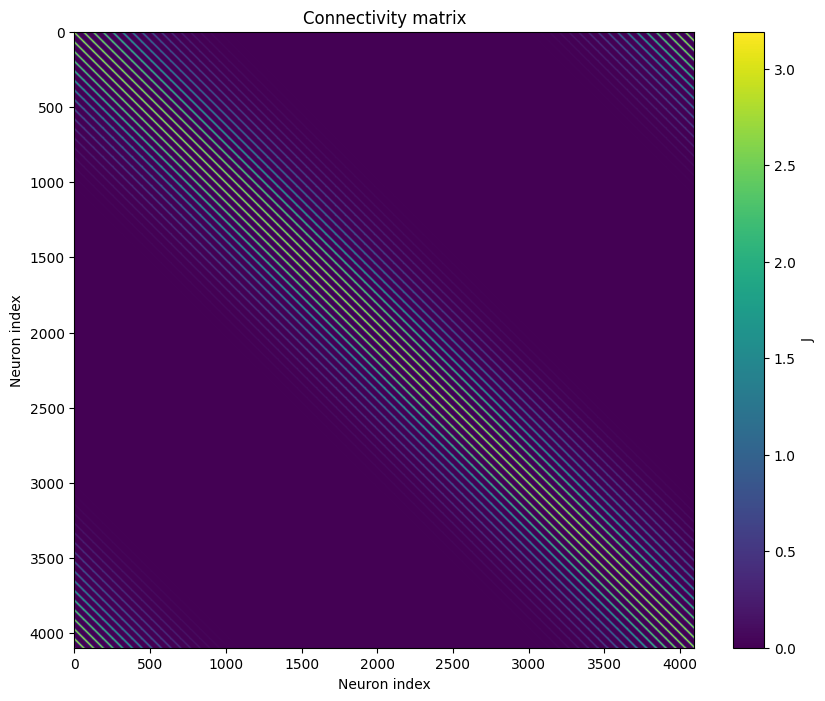

In [8]:
# 可视化 - 使用canns库的animation工具
config_2d = PlotConfigs.energy_landscape_2d_animation(
    time_steps_per_second=100,
    fps=20,
    title='CANN_2D: Smooth Tracking',
    xlabel='State X',
    ylabel='State Y',
    clabel='Activity',
    repeat=False,
    show=True,
    save_path=None,
)

energy_landscape_2d_animation(
    zs_data=us_2d,
    config=config_2d
)

# 连接矩阵可视化
plt.figure(figsize=(10, 8))
plt.imshow(bm.as_numpy(cann_2d.conn_mat), cmap='viridis', aspect='auto')
plt.colorbar(label='J')
plt.xlabel('Neuron index')
plt.ylabel('Neuron index')
plt.title('Connectivity matrix')
plt.show()